## Yerel Spark ortamı kontrolü

Spark oturumunu iki yerel iş parçacığıyla başlatıyorum. Küçük bir örnek veri üzerinde filtreleme ve sayım yaparak Notebook ortamının Spark sorgusu çalıştırabildiğini doğruluyorum.

In [2]:
import sys

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("MovieLensAtlas")
    .master("local[2]")
    .getOrCreate()
)

print("Python yolu:", sys.executable)
print("Spark sürümü:", spark.version)
print("Çalışma modu:", spark.sparkContext.master)

numbers = spark.range(5)
filtered = numbers.filter(numbers["id"] >= 2)
print("Filtre sonrası satır sayısı:", filtered.count())

Python yolu: c:\Users\busra\Projects\MovieLensAtlas\.venv\Scripts\python.exe
Spark sürümü: 4.1.1
Çalışma modu: local[2]
Filtre sonrası satır sayısı: 3


## MovieLens puan dosyasına ilk bakış

`ratings.dat` dosyasını Spark ile metin olarak okuyorum. İlk üç kaydı
inceleyerek her satırın `::` ile ayrılmış bir puan kaydı olduğunu kontrol ediyorum.

In [3]:
from pathlib import Path

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

ratings_path = project_root / "data" / "ratings.dat"

if not ratings_path.is_file():
    raise FileNotFoundError(f"Puan dosyası bulunamadı: {ratings_path}")

print("Dosya yolu:", ratings_path)

ratings_raw = spark.read.text(ratings_path.as_uri())
ratings_raw.printSchema()
ratings_raw.show(3, truncate=False)

Dosya yolu: c:\Users\busra\Projects\MovieLensAtlas\data\ratings.dat
root
 |-- value: string (nullable = true)

+---------------------+
|value                |
+---------------------+
|1::1193::5::978300760|
|1::661::3::978302109 |
|1::914::3::978301968 |
+---------------------+
only showing top 3 rows


## Puan kayıtlarının ayrıştırılması

Ham satırları `::` ayracına göre dört alana bölüyorum. Kullanıcı kimliğini,
film kimliğini ve puanı tam sayıya, zaman damgasını uzun tam sayıya
dönüştürüyorum. Alan sayısı ve tür dönüşümü hatalarını sayarak ham
kayıtların kaçının bu şemaya uyduğunu kontrol ediyorum.

In [4]:
from pyspark.sql import functions as F

ratings_parts = ratings_raw.withColumn("parts", F.split("value", "::"))

ratings_parsed = ratings_parts.select(
    F.size("parts").alias("field_count"),
    F.get("parts", 0).try_cast("int").alias("UserID"),
    F.get("parts", 1).try_cast("int").alias("MovieID"),
    F.get("parts", 2).try_cast("int").alias("Rating"),
    F.get("parts", 3).try_cast("long").alias("Timestamp"),
)

ratings = ratings_parsed.drop("field_count")
ratings.printSchema()
ratings.show(3, truncate=False)

parse_error = (
    (F.col("field_count") != 4)
    | F.col("UserID").isNull()
    | F.col("MovieID").isNull()
    | F.col("Rating").isNull()
    | F.col("Timestamp").isNull()
)

ratings_parsed.agg(
    F.count("*").alias("total_rows"),
    F.count(F.when(parse_error, 1)).alias("parse_error_rows"),
).show()

root
 |-- UserID: integer (nullable = true)
 |-- MovieID: integer (nullable = true)
 |-- Rating: integer (nullable = true)
 |-- Timestamp: long (nullable = true)

+------+-------+------+---------+
|UserID|MovieID|Rating|Timestamp|
+------+-------+------+---------+
|1     |1193   |5     |978300760|
|1     |661    |3     |978302109|
|1     |914    |3     |978301968|
+------+-------+------+---------+
only showing top 3 rows
+----------+----------------+
|total_rows|parse_error_rows|
+----------+----------------+
|   1000209|               0|
+----------+----------------+



## Film dosyasının karakter kodlaması

Film adlarındaki özel karakterlerin doğru okunması için `movies.dat`
dosyasını UTF-8 ile çözümlemeyi deniyorum. Sonucu Spark okuma ayarını
seçmek için kullanıyorum.

In [5]:
movies_path = project_root / "data" / "movies.dat"
movie_bytes = movies_path.read_bytes()

try:
    movie_text = movie_bytes.decode("utf-8")
    print("UTF-8 çözümleme başarılı.")
except UnicodeDecodeError as error:
    print("UTF-8 çözümleme başarısız.")
    print("İlk sorunlu bayt konumu:", error.start)
    print("Çözümleme hatası:", error.reason)
else:
    for line in movie_text.splitlines():
        if not line.isascii():
            print("ASCII dışı karakter içeren örnek:", line)
            break

UTF-8 çözümleme başarısız.
İlk sorunlu bayt konumu: 3114
Çözümleme hatası: invalid continuation byte


## Film başlıkları için kodlama kontrolü

UTF-8 çözümlemesinin takıldığı satırı iki aday kodlamayla okuyorum.
Dosyada bu iki kodlamanın farklı yorumladığı baytlar var mı diye kontrol
ederek Spark'ta kullanacağım kodlamayı belirliyorum.

In [6]:
position = 3114
line_start = movie_bytes.rfind(b"\n", 0, position) + 1
line_end = movie_bytes.find(b"\n", position)
raw_line = movie_bytes[line_start:line_end if line_end != -1 else len(movie_bytes)]

print("Sorunlu bayt:", hex(movie_bytes[position]))
print("Latin-1 örneği:", raw_line.decode("latin-1").rstrip())
print("Windows-1252 örneği:", raw_line.decode("cp1252", errors="replace").rstrip())

different_bytes = sorted({byte for byte in movie_bytes if 0x80 <= byte <= 0x9F})
print("İki kodlamanın ayrıştığı baytlar:", [hex(byte) for byte in different_bytes])

Sorunlu bayt: 0xe9
Latin-1 örneği: 73::Misérables, Les (1995)::Drama|Musical
Windows-1252 örneği: 73::Misérables, Les (1995)::Drama|Musical
İki kodlamanın ayrıştığı baytlar: []


## Film tablosunun okunması

`movies.dat` dosyasını ISO-8859-1 kodlaması ve `::` alan ayracıyla
okuyorum. Sütun adlarını ve tiplerini açıkça tanımlıyorum.
Satır sayısını, örnek kayıtları ve aksanlı bir film başlığını kontrol ediyorum.

In [7]:
first_line_break = movie_bytes.index(b"\n")
line_sep = "\r\n" if movie_bytes[first_line_break - 1] == 13 else "\n"

movies = (
    spark.read
    .schema("MovieID INT, Title STRING, Genres STRING")
    .option("header", False)
    .option("sep", "::")
    .option("encoding", "ISO-8859-1")
    .option("lineSep", line_sep)
    .option("quote", "")
    .option("mode", "FAILFAST")
    .csv(movies_path.as_uri())
)

movies.printSchema()
movies.show(3, truncate=False)
movies.where("MovieID = 73").show(truncate=False)

print("Ham dosyadaki satır sayısı:", len(movie_bytes.splitlines()))
print("Spark film satırı sayısı:", movies.count())

root
 |-- MovieID: integer (nullable = true)
 |-- Title: string (nullable = true)
 |-- Genres: string (nullable = true)

+-------+-----------------------+----------------------------+
|MovieID|Title                  |Genres                      |
+-------+-----------------------+----------------------------+
|1      |Toy Story (1995)       |Animation|Children's|Comedy |
|2      |Jumanji (1995)         |Adventure|Children's|Fantasy|
|3      |Grumpier Old Men (1995)|Comedy|Romance              |
+-------+-----------------------+----------------------------+
only showing top 3 rows
+-------+----------------------+-------------+
|MovieID|Title                 |Genres       |
+-------+----------------------+-------------+
|73     |Misérables, Les (1995)|Drama|Musical|
+-------+----------------------+-------------+

Ham dosyadaki satır sayısı: 3883
Spark film satırı sayısı: 3883


## Kullanıcı tablosunun okunması

Kullanıcı kayıtlarını `::` ayracına göre beş alana bölüyorum.
Yaş grubunu ve meslek kodunu tam sayı, posta kodunu metin olarak
saklıyorum. Satır sayısını ve ayrıştırma hatalarını kontrol ediyorum.

In [8]:
users_path = project_root / "data" / "users.dat"

users_raw = spark.read.text(users_path.as_uri())
users_parts = users_raw.withColumn("parts", F.split("value", "::"))

users_parsed = users_parts.select(
    F.size("parts").alias("field_count"),
    F.get("parts", 0).try_cast("int").alias("UserID"),
    F.get("parts", 1).alias("Gender"),
    F.get("parts", 2).try_cast("int").alias("Age"),
    F.get("parts", 3).try_cast("int").alias("Occupation"),
    F.get("parts", 4).alias("ZipCode"),
)

users = users_parsed.drop("field_count")
users.printSchema()
users.show(3, truncate=False)

user_parse_error = (
    (F.col("field_count") != 5)
    | F.col("UserID").isNull()
    | F.col("Age").isNull()
    | F.col("Occupation").isNull()
)

users_parsed.agg(
    F.count("*").alias("total_rows"),
    F.count(F.when(user_parse_error, 1)).alias("parse_error_rows"),
).show()

root
 |-- UserID: integer (nullable = true)
 |-- Gender: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Occupation: integer (nullable = true)
 |-- ZipCode: string (nullable = true)

+------+------+---+----------+-------+
|UserID|Gender|Age|Occupation|ZipCode|
+------+------+---+----------+-------+
|1     |F     |1  |10        |48067  |
|2     |M     |56 |16        |70072  |
|3     |M     |25 |15        |55117  |
+------+------+---+----------+-------+
only showing top 3 rows
+----------+----------------+
|total_rows|parse_error_rows|
+----------+----------------+
|      6040|               0|
+----------+----------------+



## Puan kayıtlarında veri kalitesi

Puanların 1–5 aralığında olduğunu ve zaman damgalarının dolu ve pozitif
olduğunu kontrol ediyorum. En erken ve en geç puanlama zamanını UTC
olarak gösteriyorum. Bu aşamada kayıtları değiştirmiyorum.

In [9]:
spark.conf.set("spark.sql.session.timeZone", "UTC")

invalid_rating = F.col("Rating").isNull() | ~F.col("Rating").between(1, 5)
invalid_timestamp = F.col("Timestamp").isNull() | (F.col("Timestamp") <= 0)

ratings_quality = ratings.agg(
    F.count("*").alias("total_rows"),
    F.min("Rating").alias("min_rating"),
    F.max("Rating").alias("max_rating"),
    F.count(F.when(invalid_rating, 1)).alias("invalid_rating_rows"),
    F.count(F.when(invalid_timestamp, 1)).alias("invalid_timestamp_rows"),
    F.timestamp_seconds(F.min("Timestamp")).alias("first_rating_utc"),
    F.timestamp_seconds(F.max("Timestamp")).alias("last_rating_utc"),
)

ratings_quality.show(truncate=False, vertical=True)

-RECORD 0-------------------------------------
 total_rows             | 1000209             
 min_rating             | 1                   
 max_rating             | 5                   
 invalid_rating_rows    | 0                   
 invalid_timestamp_rows | 0                   
 first_rating_utc       | 2000-04-25 23:05:32 
 last_rating_utc        | 2003-02-28 17:49:50 



## Puan kayıtlarında tekrar kontrolü

Dört alanı aynı olan kayıtları ve aynı kullanıcı–film çiftine ait
birden fazla kaydı ayrı ayrı sayıyorum. Her kontrol için tekrar
içeren grup sayısını ve her grupta bir kayıt kalsaydı kaç satırın
fazla olacağını gösteriyorum. Bu aşamada kayıtları değiştirmiyorum.

In [10]:
exact_duplicates = (
    ratings.groupBy("UserID", "MovieID", "Rating", "Timestamp")
    .count()
    .where(F.col("count") > 1)
)

repeated_pairs = (
    ratings.groupBy("UserID", "MovieID")
    .count()
    .where(F.col("count") > 1)
)

for label, groups in [
    ("Tam satır tekrarları", exact_duplicates),
    ("Kullanıcı–film çifti tekrarları", repeated_pairs),
]:
    print(label)
    groups.agg(
        F.count("*").alias("duplicate_groups"),
        F.coalesce(F.sum(F.col("count") - 1), F.lit(0)).alias("extra_rows"),
    ).show()

Tam satır tekrarları
+----------------+----------+
|duplicate_groups|extra_rows|
+----------------+----------+
|               0|         0|
+----------------+----------+

Kullanıcı–film çifti tekrarları
+----------------+----------+
|duplicate_groups|extra_rows|
+----------------+----------+
|               0|         0|
+----------------+----------+



## Film ve kullanıcı anahtarlarının kontrolü

Film tablosunda `MovieID`, kullanıcı tablosunda `UserID` alanını kontrol
ediyorum. Toplam satır sayısını, boş kimlik sayısını ve farklı kimlik
sayısını karşılaştırıyorum. Böylece bir kimliğin birden çok satıra
karşılık gelip gelmediğini görüyorum.

In [11]:
for table_name, table, key in [
    ("Film tablosu", movies, "MovieID"),
    ("Kullanıcı tablosu", users, "UserID"),
]:
    print(table_name)

    table.agg(
        F.count("*").alias("total_rows"),
        F.count(F.when(F.col(key).isNull(), 1)).alias("null_keys"),
        F.countDistinct(key).alias("distinct_keys"),
    ).show()

Film tablosu
+----------+---------+-------------+
|total_rows|null_keys|distinct_keys|
+----------+---------+-------------+
|      3883|        0|         3883|
+----------+---------+-------------+

Kullanıcı tablosu
+----------+---------+-------------+
|total_rows|null_keys|distinct_keys|
+----------+---------+-------------+
|      6040|        0|         6040|
+----------+---------+-------------+



## Puan kayıtlarında anahtar eşleşmesi

Her puan kaydındaki film ve kullanıcı kimliğini ilgili tabloda arıyorum.
Karşılığı bulunmayan puan satırlarını iki ayrı sayaçla gösteriyorum.
Bu kontrol sırasında puan tablosunu değiştirmiyorum.

In [12]:
ratings_without_movie = ratings.join(
    movies.select("MovieID"), on="MovieID", how="left_anti"
)

ratings_without_user = ratings.join(
    users.select("UserID"), on="UserID", how="left_anti"
)

print("Film eşleşmesi olmayan puan satırları:", ratings_without_movie.count())
print("Kullanıcı eşleşmesi olmayan puan satırları:", ratings_without_user.count())

Film eşleşmesi olmayan puan satırları: 0
Kullanıcı eşleşmesi olmayan puan satırları: 0


## Film ve kullanıcı alanlarının kalite kontrolü

Film adı ve türü boş olan kayıtları sayıyorum. İsteğe bağlı yaş analizi
için kullanıcıların yaş grubu kodlarını MovieLens 1M’deki geçerli
kodlarla karşılaştırıyorum. Bu adımda kayıtları değiştirmiyorum.

In [13]:
blank_title = F.col("Title").isNull() | (F.trim(F.col("Title")) == "")
blank_genres = F.col("Genres").isNull() | (F.trim(F.col("Genres")) == "")

valid_age_codes = [1, 18, 25, 35, 45, 50, 56]
invalid_age = F.col("Age").isNull() | ~F.col("Age").isin(valid_age_codes)

print("Film alanları")
movies.agg(
    F.count(F.when(blank_title, 1)).alias("blank_titles"),
    F.count(F.when(blank_genres, 1)).alias("blank_genres"),
).show()

print("Kullanıcı yaş kodları")
users.agg(
    F.count(F.when(invalid_age, 1)).alias("invalid_age_codes"),
).show()

Film alanları
+------------+------------+
|blank_titles|blank_genres|
+------------+------------+
|           0|           0|
+------------+------------+

Kullanıcı yaş kodları
+-----------------+
|invalid_age_codes|
+-----------------+
|                0|
+-----------------+



## Veri kalitesi kontrollerinin sonucu

Puan kayıtlarında geçersiz puan, eksik veya pozitif olmayan zaman
damgası, tam satır tekrarı ve kullanıcı–film çifti tekrarı bulmadım.
Film ve kullanıcı kimlikleri dolu ve tekil. Her puan kaydı ilgili
film ve kullanıcıyla eşleşiyor. Film adı ve tür alanları dolu,
yaş grubu kodları geçerli.

Bu kontroller sonucunda hiçbir kayıt çıkarmadım. Okuma sonrasında
ve analiz öncesinde satır sayıları aynı kaldı.

| Tablo | Okuma sonrası | Analiz öncesi | Çıkarılan kayıt |
| --- | ---: | ---: | ---: |
| Puanlar | 1.000.209 | 1.000.209 | 0 |
| Filmler | 3.883 | 3.883 | 0 |
| Kullanıcılar | 6.040 | 6.040 | 0 |

## Genel puan dağılımı

Her yıldız değeri için kaç puan kaydı olduğunu Spark ile hesaplıyorum.
Her sayıyı toplam puan kaydına bölerek yüzdesini buluyorum. Bu tablo,
türlere göre puanları incelerken genel dağılımla karşılaştırma yapmamı
sağlayacak.

In [14]:
total_ratings = ratings.count()

rating_distribution = (
    ratings.groupBy("Rating")
    .agg(F.count("*").alias("rating_count"))
    .withColumn(
        "rating_pct",
        F.col("rating_count") * 100.0 / total_ratings,
    )
    .orderBy("Rating")
)

rating_distribution.show()

rating_distribution.agg(
    F.sum("rating_count").alias("total_count"),
    F.round(F.sum("rating_pct"), 2).alias("total_pct"),
).show()

+------+------------+------------------+
|Rating|rating_count|        rating_pct|
+------+------------+------------------+
|     1|       56174| 5.616226208722377|
|     2|      107557| 10.75345252842156|
|     3|      261197| 26.11424212339621|
|     4|      348971|34.889808030121706|
|     5|      226310| 22.62627110933815|
+------+------------+------------------+

+-----------+---------+
|total_count|total_pct|
+-----------+---------+
|    1000209|    100.0|
+-----------+---------+



### Yıldızlara göre puanların yüzdesi

Spark'ta hesapladığım beş satırlık özeti Pandas'a aktarıp
Matplotlib ile çiziyorum. Her sütun, bir yıldız değerinin
tüm puan kayıtları içindeki yüzdesini gösteriyor.

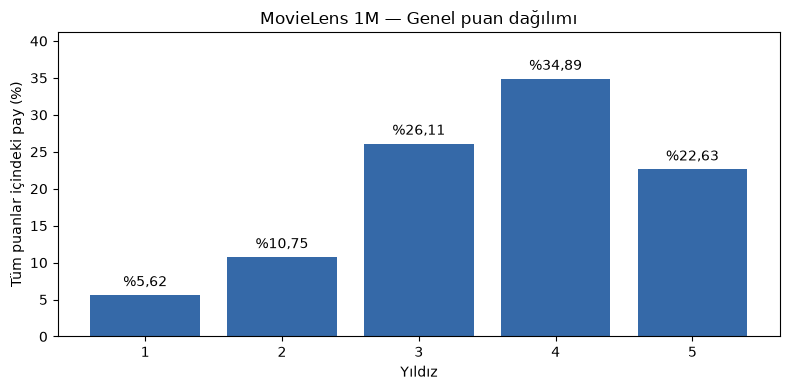

In [15]:
import matplotlib.pyplot as plt

rating_plot = rating_distribution.toPandas()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(rating_plot["Rating"], rating_plot["rating_pct"], color="#3569A8")

ax.set_title("MovieLens 1M — Genel puan dağılımı")
ax.set_xlabel("Yıldız")
ax.set_ylabel("Tüm puanlar içindeki pay (%)")
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_ylim(0, rating_plot["rating_pct"].max() * 1.18)
ax.bar_label(
    bars,
    labels=[f"%{pct:.2f}".replace(".", ",") for pct in rating_plot["rating_pct"]],
    padding=4,
)

fig.tight_layout()
plt.show()

### Genel puan dağılımının yorumu

MovieLens 1M’de en sık verilen puan 4 yıldızdır. 348.971 kayıtla
tüm puanların %34,89’unu oluşturur. 4 ve 5 yıldız birlikte tüm
puanların %57,52’sini oluşturur. Tür analizinde 4–5 yıldız oranlarını
bu veri seti geneliyle karşılaştıracağım.

## Puan ve film tablolarının birleştirilmesi

Puan kayıtlarına film adını ve türlerini eklemek için iki tabloyu
`MovieID` üzerinden birleştiriyorum. Birleştirmeden önceki ve sonraki
satır sayılarını karşılaştırarak her puan kaydının korunduğunu
kontrol ediyorum.

In [16]:
ratings_with_movies = ratings.join(
    movies.select("MovieID", "Title", "Genres"),
    on="MovieID",
    how="inner",
)

joined_rating_count = ratings_with_movies.count()

print("Birleştirme öncesi:", total_ratings)
print("Birleştirme sonrası:", joined_rating_count)
print("Satır farkı:", joined_rating_count - total_ratings)

ratings_with_movies.select(
    "UserID", "MovieID", "Rating", "Title", "Genres"
).show(5, truncate=False)

Birleştirme öncesi: 1000209
Birleştirme sonrası: 1000209
Satır farkı: 0
+------+-------+------+--------------------------------------+----------------------------+
|UserID|MovieID|Rating|Title                                 |Genres                      |
+------+-------+------+--------------------------------------+----------------------------+
|1     |1193   |5     |One Flew Over the Cuckoo's Nest (1975)|Drama                       |
|1     |661    |3     |James and the Giant Peach (1996)      |Animation|Children's|Musical|
|1     |914    |3     |My Fair Lady (1964)                   |Musical|Romance             |
|1     |3408   |4     |Erin Brockovich (2000)                |Drama                       |
|1     |2355   |5     |Bug's Life, A (1998)                  |Animation|Children's|Comedy |
+------+-------+------+--------------------------------------+----------------------------+
only showing top 5 rows


## Film türlerinin ayrı satırlara açılması

Tür etiketlerini `|` işaretinden ayırıp her puan–tür çifti için bir
satır oluşturuyorum. Açılan satır sayısını, açma öncesinde puan
kayıtlarına bağlı tür etiketi sayısıyla karşılaştırıyorum.

In [17]:
ratings_with_genre_lists = ratings_with_movies.withColumn(
    "GenreList",
    F.array_distinct(F.split("Genres", r"\|")),
)

ratings_by_genre = ratings_with_genre_lists.select(
    "UserID",
    "MovieID",
    "Rating",
    F.explode("GenreList").alias("Genre"),
)

expected_genre_rows = ratings_with_genre_lists.agg(
    F.sum(F.size("GenreList")).alias("expected_rows")
).first()["expected_rows"]

actual_genre_rows = ratings_by_genre.count()

print("Açma öncesi puan satırı:", joined_rating_count)
print("Beklenen puan–tür satırı:", expected_genre_rows)
print("Oluşan puan–tür satırı:", actual_genre_rows)
print("Beklenen ile oluşan arasındaki fark:", actual_genre_rows - expected_genre_rows)

ratings_by_genre.where(
    (F.col("UserID") == 1) & (F.col("MovieID") == 661)
).orderBy("Genre").show(truncate=False)

Açma öncesi puan satırı: 1000209
Beklenen puan–tür satırı: 2101815
Oluşan puan–tür satırı: 2101815
Beklenen ile oluşan arasındaki fark: 0
+------+-------+------+----------+
|UserID|MovieID|Rating|Genre     |
+------+-------+------+----------+
|1     |661    |3     |Animation |
|1     |661    |3     |Children's|
|1     |661    |3     |Musical   |
+------+-------+------+----------+



## Türlere göre puanlama özeti

Her tür için puan kaydı sayısını, ortalama puanı ve 4–5 yıldız alan
kayıtların yüzdesini hesaplıyorum. Yüksek puan yüzdesinin paydası,
ilgili türün tüm puan kayıtlarıdır. Tür sayımlarının toplamını
türleri açtıktan sonra elde ettiğim satır sayısıyla karşılaştırıyorum.

In [18]:
genre_summary = (
    ratings_by_genre.groupBy("Genre")
    .agg(
        F.count("*").alias("rating_count"),
        F.avg("Rating").alias("avg_rating"),
        F.count(F.when(F.col("Rating") >= 4, 1)).alias("high_rating_count"),
    )
    .withColumn(
        "high_rating_pct",
        100.0 * F.col("high_rating_count") / F.col("rating_count"),
    )
    .orderBy(F.desc("rating_count"), F.asc("Genre"))
)

genre_summary.select(
    "Genre",
    "rating_count",
    F.round("avg_rating", 2).alias("avg_rating"),
    "high_rating_count",
    F.round("high_rating_pct", 2).alias("high_rating_pct"),
).show(truncate=False)

summary_genre_rows = genre_summary.agg(
    F.sum("rating_count").alias("total")
).first()["total"]

print("Tür özetindeki toplam:", summary_genre_rows)
print("Açılan satır sayısına göre fark:", summary_genre_rows - actual_genre_rows)

+-----------+------------+----------+-----------------+---------------+
|Genre      |rating_count|avg_rating|high_rating_count|high_rating_pct|
+-----------+------------+----------+-----------------+---------------+
|Comedy     |356580      |3.52      |196945           |55.23          |
|Drama      |354529      |3.77      |228440           |64.43          |
|Action     |257457      |3.49      |138766           |53.9           |
|Thriller   |189680      |3.57      |108216           |57.05          |
|Sci-Fi     |157294      |3.47      |83197            |52.89          |
|Romance    |147523      |3.61      |85499            |57.96          |
|Adventure  |133953      |3.48      |70951            |52.97          |
|Crime      |79541       |3.71      |49347            |62.04          |
|Horror     |76386       |3.22      |34088            |44.63          |
|Children's |72186       |3.42      |37278            |51.64          |
|War        |68527       |3.89      |47542            |69.38    

### Türlere göre puan sayısı ve yüksek puan oranı

Solda her türün puan kaydı sayısını, sağda o türdeki puanların
yüzde kaçının 4 veya 5 yıldız olduğunu gösteriyorum. Kesikli çizgi,
türler açılmadan önce tüm puanlardan hesapladığım genel oranı gösteriyor.
Bir film birden fazla türe ait olabildiği için aynı puan birden çok
türün hesabına girebilir.

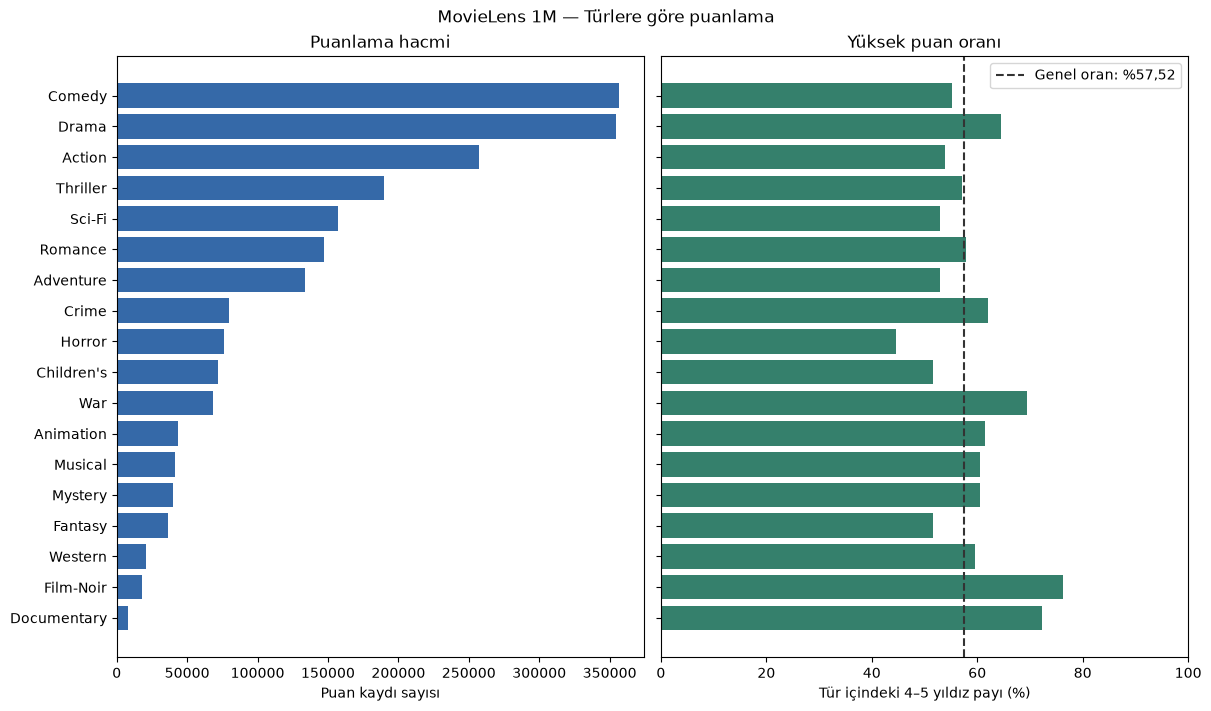

In [19]:
genre_plot = genre_summary.select(
    "Genre", "rating_count", "high_rating_pct"
).toPandas()

overall_high_pct = rating_plot.loc[
    rating_plot["Rating"].isin([4, 5]), "rating_pct"
].sum()

fig, (ax_count, ax_pct) = plt.subplots(
    1, 2, figsize=(12, 7), sharey=True, layout="constrained"
)

ax_count.barh(genre_plot["Genre"], genre_plot["rating_count"], color="#3569A8")
ax_count.invert_yaxis()
ax_count.set_title("Puanlama hacmi")
ax_count.set_xlabel("Puan kaydı sayısı")

ax_pct.barh(genre_plot["Genre"], genre_plot["high_rating_pct"], color="#35806C")
ax_pct.axvline(
    overall_high_pct,
    color="#333333",
    linestyle="--",
    label=f"Genel oran: %{overall_high_pct:.2f}".replace(".", ","),
)
ax_pct.set_xlim(0, 100)
ax_pct.set_title("Yüksek puan oranı")
ax_pct.set_xlabel("Tür içindeki 4–5 yıldız payı (%)")
ax_pct.legend(loc="upper right")

fig.suptitle("MovieLens 1M — Türlere göre puanlama")
plt.show()

### Türlere göre puanlamanın yorumu

Comedy ve Drama, en çok puan kaydı olan iki türdür. Puan sayıları
birbirine yakın olsa da 4–5 yıldız oranı Drama'da %64,43,
Comedy'de %55,23'tür. Aradaki fark 9,20 yüzde puanıdır.

Film-Noir, 18.261 puan kaydında %76,35 ile en yüksek 4–5 yıldız
oranına ve 4,08 ile en yüksek ortalama puana sahiptir. Bu oranlar
MovieLens kullanıcılarının verdiği puanları gösterir. Bir film
birden çok türe ait olduğunda puanı her türün hesabına girer.

## Film başına puan özeti

Puanları film kimliğine göre grupluyorum. Her film için puan sayısını,
ortalama puanı ve puanların standart sapmasını hesaplıyorum. Film adını
gruplamadan sonra ekliyorum. Özetin her film için tek satır içerdiğini
ve puan sayılarının toplamının kaynak tabloyla eşleştiğini kontrol ediyorum.

In [20]:
film_summary = (
    ratings.groupBy("MovieID")
    .agg(
        F.count("*").alias("rating_count"),
        F.avg("Rating").alias("avg_rating"),
        F.stddev_samp("Rating").alias("rating_stddev"),
    )
    .join(movies.select("MovieID", "Title"), on="MovieID", how="inner")
    .select("MovieID", "Title", "rating_count", "avg_rating", "rating_stddev")
)

film_summary.orderBy("MovieID").show(5, truncate=False)

film_summary.agg(
    F.count("*").alias("film_rows"),
    F.countDistinct("MovieID").alias("distinct_movie_ids"),
    F.sum("rating_count").alias("total_rating_count"),
).show()

+-------+----------------------------------+------------+------------------+------------------+
|MovieID|Title                             |rating_count|avg_rating        |rating_stddev     |
+-------+----------------------------------+------------+------------------+------------------+
|1      |Toy Story (1995)                  |2077        |4.146846413095811 |0.8523490842765876|
|2      |Jumanji (1995)                    |701         |3.20114122681883  |0.9831720435251147|
|3      |Grumpier Old Men (1995)           |478         |3.01673640167364  |1.071711838975395 |
|4      |Waiting to Exhale (1995)          |170         |2.7294117647058824|1.0133807183552217|
|5      |Father of the Bride Part II (1995)|296         |3.0067567567567566|1.0250861666741646|
+-------+----------------------------------+------------+------------------+------------------+
only showing top 5 rows
+---------+------------------+------------------+
|film_rows|distinct_movie_ids|total_rating_count|
+---------+-

### Film başına puan sayısı dağılımı

Filmlerin kaç puan aldığını yüzdeliklerle özetliyorum. En az 50 ve
en az 100 puan koşullarında kaç filmin kaldığını ve bu filmlerin
tüm puanların ne kadarını kapsadığını karşılaştırıyorum. Bu çıktıyı
ilk 10 sıralamalarında kullanacağım eşiği belirlemek için kullanacağım.

In [21]:
film_summary.agg(
    F.min("rating_count").alias("min_ratings"),
    F.percentile_approx("rating_count", 0.25).alias("p25"),
    F.percentile_approx("rating_count", 0.50).alias("median"),
    F.percentile_approx("rating_count", 0.75).alias("p75"),
    F.percentile_approx("rating_count", 0.90).alias("p90"),
    F.max("rating_count").alias("max_ratings"),
).show()

for threshold in [50, 100]:
    print(f"En az {threshold} puan")
    (
        film_summary.where(F.col("rating_count") >= threshold)
        .agg(
            F.count("*").alias("eligible_films"),
            F.sum("rating_count").alias("covered_ratings"),
        )
        .withColumn(
            "covered_rating_pct",
            F.round(100.0 * F.col("covered_ratings") / total_ratings, 2),
        )
        .show()
    )

+-----------+---+------+---+---+-----------+
|min_ratings|p25|median|p75|p90|max_ratings|
+-----------+---+------+---+---+-----------+
|          1| 33|   123|350|730|       3428|
+-----------+---+------+---+---+-----------+

En az 50 puan
+--------------+---------------+------------------+
|eligible_films|covered_ratings|covered_rating_pct|
+--------------+---------------+------------------+
|          2514|         977839|             97.76|
+--------------+---------------+------------------+

En az 100 puan
+--------------+---------------+------------------+
|eligible_films|covered_ratings|covered_rating_pct|
+--------------+---------------+------------------+
|          2019|         942225|              94.2|
+--------------+---------------+------------------+



### En çok puanlanan ve en yüksek ortalamalı filmler

En az 100 puan almış filmlerden iki ilk 10 listesi oluşturuyorum.
Birini puan sayısına, diğerini ortalama puana göre sıralıyorum.
İki listede de yer alan filmleri MovieID üzerinden eşleştirip
örtüşme oranını hesaplıyorum.

In [22]:
min_rating_count = 100
top_n = 10

eligible_films = film_summary.where(F.col("rating_count") >= min_rating_count)

top_by_count = eligible_films.orderBy(
    F.desc("rating_count"), F.asc("MovieID")
).limit(top_n)

top_by_average = eligible_films.orderBy(
    F.desc("avg_rating"), F.desc("rating_count"), F.asc("MovieID")
).limit(top_n)

print("Puan sayısına göre ilk 10")
top_by_count.show(top_n, truncate=False)

print("Ortalama puana göre ilk 10")
top_by_average.show(top_n, truncate=False)

shared_films = top_by_count.join(
    top_by_average.select("MovieID"), on="MovieID", how="inner"
)

shared_count = shared_films.count()
print(f"Ortak film sayısı: {shared_count}/{top_n}")
print(f"Örtüşme oranı: %{100 * shared_count / top_n:.0f}")

shared_films.orderBy(F.desc("rating_count"), F.asc("MovieID")).select(
    "MovieID", "Title", "rating_count", "avg_rating"
).show(top_n, truncate=False)

Puan sayısına göre ilk 10
+-------+-----------------------------------------------------+------------+------------------+------------------+
|MovieID|Title                                                |rating_count|avg_rating        |rating_stddev     |
+-------+-----------------------------------------------------+------------+------------------+------------------+
|2858   |American Beauty (1999)                               |3428        |4.3173862310385065|0.975133456726424 |
|260    |Star Wars: Episode IV - A New Hope (1977)            |2991        |4.453694416583082 |0.8007806969749864|
|1196   |Star Wars: Episode V - The Empire Strikes Back (1980)|2990        |4.292976588628763 |0.8444320039457232|
|1210   |Star Wars: Episode VI - Return of the Jedi (1983)    |2883        |4.022892819979188 |0.9273560638806962|
|480    |Jurassic Park (1993)                                 |2672        |3.7638473053892216|0.9697768349391782|
|2028   |Saving Private Ryan (1998)                   

### Asgari değerlendirme sayısının ortalama puan sıralamasına etkisi

Ortalama puana göre iki ilk 10 listesi oluşturuyorum. İlk listeye
puan almış bütün filmler, ikinci listeye en az 50 değerlendirme
alan filmler aday oluyor. Her iki listede de aynı sıralama kurallarını
kullanıyorum.

Filmleri ortalama puana göre azalan sırada diziyorum. Ortalamalar
eşitse daha çok değerlendirme alan filmi öne alıyorum. Eşitlik
sürerse MovieID değeri küçük olan film önce geliyor. Film kimliklerini
karşılaştırarak 50 değerlendirme eşiğinin ilk 10 listesini nasıl
değiştirdiğini inceliyorum.

In [23]:
threshold_comparison_count = 50

average_sort_order = [
    F.desc("avg_rating"),
    F.desc("rating_count"),
    F.asc("MovieID"),
]

top_average_all = film_summary.orderBy(*average_sort_order).limit(top_n)

top_average_min_50 = (
    film_summary
    .where(F.col("rating_count") >= threshold_comparison_count)
    .orderBy(*average_sort_order)
    .limit(top_n)
)

for label, ranking in [
    ("Ortalama puana göre ilk 10 — eşiksiz", top_average_all),
    ("Ortalama puana göre ilk 10 — en az 50 değerlendirme", top_average_min_50),
]:
    print(label)
    ranking.orderBy(*average_sort_order).select(
        "MovieID",
        "Title",
        "rating_count",
        F.round("avg_rating", 3).alias("avg_rating"),
    ).show(top_n, truncate=False)

all_top_ids = {row.MovieID for row in top_average_all.select("MovieID").collect()}
min_50_top_ids = {
    row.MovieID for row in top_average_min_50.select("MovieID").collect()
}

print(f"Ortak film sayısı: {len(all_top_ids & min_50_top_ids)}/{top_n}")
print("Eşik uygulanınca ilk 10 listesinden çıkan film sayısı:",
      len(all_top_ids - min_50_top_ids))

Ortalama puana göre ilk 10 — eşiksiz
+-------+-----------------------------------------+------------+----------+
|MovieID|Title                                    |rating_count|avg_rating|
+-------+-----------------------------------------+------------+----------+
|787    |Gate of Heavenly Peace, The (1995)       |3           |5.0       |
|3233   |Smashing Time (1967)                     |2           |5.0       |
|989    |Schlafes Bruder (Brother of Sleep) (1995)|1           |5.0       |
|1830   |Follow the Bitch (1998)                  |1           |5.0       |
|3172   |Ulysses (Ulisse) (1954)                  |1           |5.0       |
|3280   |Baby, The (1973)                         |1           |5.0       |
|3382   |Song of Freedom (1936)                   |1           |5.0       |
|3607   |One Little Indian (1973)                 |1           |5.0       |
|3656   |Lured (1947)                             |1           |5.0       |
|3881   |Bittersweet Motel (2000)                 |

#### 50 değerlendirme eşiğinin sıralamaya etkisi

Eşiksiz ilk 10'daki bütün filmlerin ortalaması 5,00'dı. Ancak bu
ortalamalar film başına yalnızca 1 ila 3 değerlendirmeye dayanıyordu.
En az 50 değerlendirme şartı uygulandığında iki ilk 10 listesinde
ortak film kalmadı. Sanjuro (1962), 69 değerlendirme ve 4,609
ortalamayla eşikli listenin ilk sırasına yerleşti.

İki listede aynı sıralama kurallarını kullandım. Gözlenen değişim,
bu veri setinde asgari değerlendirme sayısının ilk 10 listesini
nasıl etkilediğini gösteriyor.

### En çok puanlanan 50 filmde puanların yoğunlaşması

Tüm puanlanmış filmleri puan sayısına göre sıralıyorum. İlk 50 filmin
aldığı puanların toplamını, veri setindeki tüm puan kayıtlarına bölüyorum.
Bu oran, toplam puanlama hacminin ne kadarının ilk 50 filme ait olduğunu
gösteriyor.

In [24]:
top_50_films = film_summary.orderBy(
    F.desc("rating_count"), F.asc("MovieID")
).limit(50)

top_50_share = top_50_films.agg(
    F.count("*").alias("film_count"),
    F.sum("rating_count").alias("top_50_rating_count"),
).withColumn(
    "total_rating_count",
    F.lit(total_ratings),
).withColumn(
    "top_50_rating_pct",
    F.round(100.0 * F.col("top_50_rating_count") / F.col("total_rating_count"), 2),
)

top_50_share.show()

+----------+-------------------+------------------+-----------------+
|film_count|top_50_rating_count|total_rating_count|top_50_rating_pct|
+----------+-------------------+------------------+-----------------+
|        50|             109804|           1000209|            10.98|
+----------+-------------------+------------------+-----------------+



### Film sıralamalarının ve yoğunlaşmanın yorumu

En az 100 puan alan filmler arasında, puan sayısına göre ilk 10 ile
ortalama puana göre ilk 10 arasında ortak film bulunmadı. Tüm puanlanmış
filmler üzerinden hesapladığımda, en çok puanlanan 50 film toplam
109.804 puanla tüm puanların %10,98’ini aldı.

In [25]:
a = eligible_films.alias("a")
b = eligible_films.alias("b")

film_pair_candidates = (
    a.join(
        b,
        (F.col("a.MovieID") < F.col("b.MovieID"))
        & (F.abs(F.col("a.avg_rating") - F.col("b.avg_rating")) <= 0.10)
        & (
            F.least(F.col("a.rating_count"), F.col("b.rating_count"))
            >= 0.80 * F.greatest(F.col("a.rating_count"), F.col("b.rating_count"))
        ),
        how="inner",
    )
    .select(
        F.col("a.MovieID").alias("movie_id_a"),
        F.col("a.Title").alias("title_a"),
        F.col("a.rating_count").alias("rating_count_a"),
        F.col("a.avg_rating").alias("avg_rating_a"),
        F.col("a.rating_stddev").alias("stddev_a"),
        F.col("b.MovieID").alias("movie_id_b"),
        F.col("b.Title").alias("title_b"),
        F.col("b.rating_count").alias("rating_count_b"),
        F.col("b.avg_rating").alias("avg_rating_b"),
        F.col("b.rating_stddev").alias("stddev_b"),
    )
    .withColumn("avg_gap", F.abs(F.col("avg_rating_a") - F.col("avg_rating_b")))
    .withColumn("stddev_gap", F.abs(F.col("stddev_a") - F.col("stddev_b")))
)

selected_film_pair = (
    film_pair_candidates
    .withColumn(
        "rating_count_ratio_pct",
        100.0
        * F.least("rating_count_a", "rating_count_b")
        / F.greatest("rating_count_a", "rating_count_b"),
    )
    .orderBy(
        F.desc("stddev_gap"),
        F.asc("avg_gap"),
        F.asc("movie_id_a"),
        F.asc("movie_id_b"),
    )
    .limit(1)
)

print("Aday koşulları")
print(f"- Her film en az {min_rating_count} puan almış olmalı.")
print("- Ortalama puan farkı en fazla 0,10 yıldız olmalı.")
print("- Daha az puanlanan filmin puan sayısı diğerinin en az %80'i olmalı.")
print("Seçim ölçütü: Adaylar arasındaki en büyük standart sapma farkı.")

selected_film_pair.select(
    "title_a",
    "title_b",
    "rating_count_a",
    "rating_count_b",
    F.round("rating_count_ratio_pct", 1).alias("rating_count_ratio_pct"),
    F.round("avg_rating_a", 3).alias("avg_rating_a"),
    F.round("avg_rating_b", 3).alias("avg_rating_b"),
    F.round("avg_gap", 3).alias("avg_gap"),
    F.round("stddev_a", 3).alias("stddev_a"),
    F.round("stddev_b", 3).alias("stddev_b"),
    F.round("stddev_gap", 3).alias("stddev_gap"),
).show(truncate=False, vertical=True)

Aday koşulları
- Her film en az 100 puan almış olmalı.
- Ortalama puan farkı en fazla 0,10 yıldız olmalı.
- Daha az puanlanan filmin puan sayısı diğerinin en az %80'i olmalı.
Seçim ölçütü: Adaylar arasındaki en büyük standart sapma farkı.
-RECORD 0-------------------------------------------
 title_a                | Soldier's Story, A (1984) 
 title_b                | Dancer in the Dark (2000) 
 rating_count_a         | 164                       
 rating_count_b         | 200                       
 rating_count_ratio_pct | 82.0                      
 avg_rating_a           | 3.738                     
 avg_rating_b           | 3.82                      
 avg_gap                | 0.082                     
 stddev_a               | 0.725                     
 stddev_b               | 1.251                     
 stddev_gap             | 0.526                     



### Seçilen iki filmin yıldız dağılımı

Her film için 1–5 yıldızın kaç kez verildiğini ve filmin kendi
puanları içindeki yüzdesini hesaplıyorum. Hiç verilmemiş yıldız
değerlerini sıfırla gösteriyorum. Film başına toplamı, film
özetindeki puan sayısıyla karşılaştırıyorum.

In [26]:
pair = selected_film_pair.first()

selected_films = film_summary.where(
    F.col("MovieID").isin(pair["movie_id_a"], pair["movie_id_b"])
).select(
    "MovieID", "Title", F.col("rating_count").alias("film_rating_count")
)

selected_rating_counts = (
    ratings.join(selected_films.select("MovieID"), on="MovieID", how="inner")
    .groupBy("MovieID", "Rating")
    .agg(F.count("*").alias("rating_count"))
)

star_values = spark.range(1, 6).select(F.col("id").cast("int").alias("Rating"))

film_rating_distribution = (
    selected_films.crossJoin(star_values)
    .join(selected_rating_counts, on=["MovieID", "Rating"], how="left")
    .fillna(0, subset=["rating_count"])
    .withColumn("rating_pct", 100.0 * F.col("rating_count") / F.col("film_rating_count"))
)

film_rating_distribution.orderBy("MovieID", "Rating").select(
    "MovieID", "Title", "Rating", "rating_count",
    F.round("rating_pct", 2).alias("rating_pct"),
).show(truncate=False)

film_rating_distribution.groupBy("MovieID", "film_rating_count").agg(
    F.sum("rating_count").alias("total_count"),
    F.round(F.sum("rating_pct"), 2).alias("total_pct"),
).orderBy("MovieID").show()

+-------+-------------------------+------+------------+----------+
|MovieID|Title                    |Rating|rating_count|rating_pct|
+-------+-------------------------+------+------------+----------+
|2852   |Soldier's Story, A (1984)|1     |2           |1.22      |
|2852   |Soldier's Story, A (1984)|2     |1           |0.61      |
|2852   |Soldier's Story, A (1984)|3     |55          |33.54     |
|2852   |Soldier's Story, A (1984)|4     |86          |52.44     |
|2852   |Soldier's Story, A (1984)|5     |20          |12.2      |
|3910   |Dancer in the Dark (2000)|1     |15          |7.5       |
|3910   |Dancer in the Dark (2000)|2     |16          |8.0       |
|3910   |Dancer in the Dark (2000)|3     |39          |19.5      |
|3910   |Dancer in the Dark (2000)|4     |50          |25.0      |
|3910   |Dancer in the Dark (2000)|5     |80          |40.0      |
+-------+-------------------------+------+------------+----------+

+-------+-----------------+-----------+---------+
|MovieID|fi

### Bu iki filmi neden seçtim?

A Soldier’s Story ve Dancer in the Dark sırasıyla 164 ve 200 puan aldı.
İkisi de 100 puan eşiğini geçti. Puan sayılarının oranı %82 ve ortalama
puan farkı 0,082 yıldız olduğu için bu çift aday oldu.

Aday çiftleri standart sapma farkına göre sıraladım. Bu çift 0,526 ile
en büyük farka sahipti. Böylece benzer ortalamalara sahip iki filmin
puanlarının ne kadar farklı yayılabildiğini gösteren bir örnek seçtim.
Film türü seçim ölçütleri arasında yer almadı.

### İki filmin yıldız dağılımının karşılaştırılması

Her yıldız değeri için iki filmin yüzdelerini yan yana gösteriyorum.
Her yüzdeyi filmin kendi puan sayısına böldüğüm için 164 ve 200
puanlık iki dağılımı aynı ölçekte karşılaştırabiliyorum.

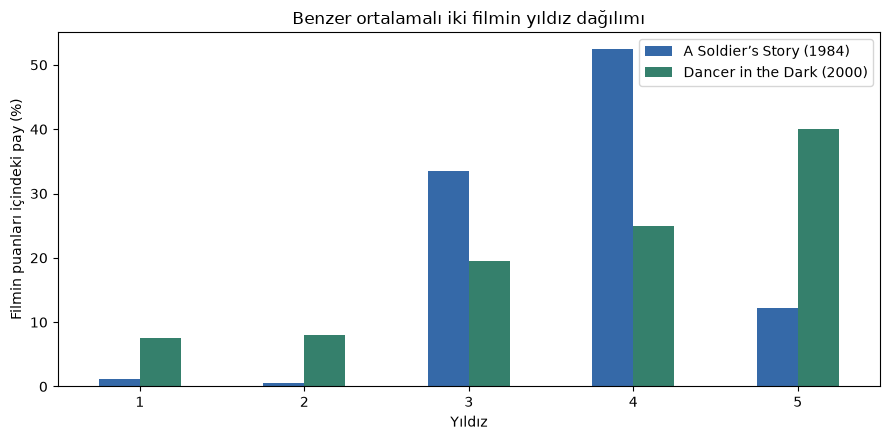

In [27]:
pair_plot = film_rating_distribution.select(
    "MovieID", "Rating", "rating_pct"
).toPandas()

star_shares = pair_plot.pivot(
    index="Rating",
    columns="MovieID",
    values="rating_pct",
).sort_index()

ax = star_shares[[pair["movie_id_a"], pair["movie_id_b"]]].plot.bar(
    figsize=(9, 4.5),
    color=["#3569A8", "#35806C"],
    rot=0,
)

ax.set_title("Benzer ortalamalı iki filmin yıldız dağılımı")
ax.set_xlabel("Yıldız")
ax.set_ylabel("Filmin puanları içindeki pay (%)")
ax.legend(["A Soldier’s Story (1984)", "Dancer in the Dark (2000)"])

ax.figure.tight_layout()
plt.show()

### İki filmin puan dağılımının yorumu

A Soldier’s Story ve Dancer in the Dark’ın ortalama puanları
sırasıyla 3,74 ve 3,82’dir. A Soldier’s Story’de puanların yaklaşık
%86’sı 3 veya 4 yıldızdır. Dancer in the Dark’ta puanların %40’ı
5 yıldız, %15,50’si 1 veya 2 yıldızdır. Bu daha geniş yayılım,
filmin standart sapmasının daha yüksek olmasıyla uyumludur.

## Aylık puanlama etkinliği

Puanların zaman damgalarını UTC takvim ayına dönüştürüyorum.
Her ay için toplam puan sayısını ve o ay en az bir puan veren
benzersiz kullanıcı sayısını hesaplıyorum. Aylık puan sayılarının
toplamını kaynak tablodaki kayıt sayısıyla karşılaştırıyorum.

In [28]:
spark.conf.set("spark.sql.session.timeZone", "UTC")

monthly_activity = (
    ratings.withColumn(
        "rating_month",
        F.date_trunc("month", F.timestamp_seconds("Timestamp")).cast("date"),
    )
    .groupBy("rating_month")
    .agg(
        F.count("*").alias("rating_count"),
        F.countDistinct("UserID").alias("active_users"),
    )
    .orderBy("rating_month")
)

monthly_activity.show(36, truncate=False)

monthly_activity.agg(
    F.count("*").alias("observed_months"),
    F.sum("rating_count").alias("total_rating_count"),
    F.min("rating_month").alias("first_month"),
    F.max("rating_month").alias("last_month"),
    F.count(
        F.when(F.col("active_users") > F.col("rating_count"), 1)
    ).alias("months_with_invalid_counts"),
).show()

+------------+------------+------------+
|rating_month|rating_count|active_users|
+------------+------------+------------+
|2000-04-01  |11396       |86          |
|2000-05-01  |67437       |486         |
|2000-06-01  |54486       |508         |
|2000-07-01  |90334       |778         |
|2000-08-01  |182109      |1310        |
|2000-09-01  |52421       |576         |
|2000-10-01  |42294       |500         |
|2000-11-01  |290793      |2357        |
|2000-12-01  |113487      |1241        |
|2001-01-01  |18004       |543         |
|2001-02-01  |8136        |395         |
|2001-03-01  |6083        |323         |
|2001-04-01  |5171        |293         |
|2001-05-01  |4939        |274         |
|2001-06-01  |4981        |271         |
|2001-07-01  |4765        |290         |
|2001-08-01  |4454        |246         |
|2001-09-01  |3077        |191         |
|2001-10-01  |2192        |180         |
|2001-11-01  |2760        |180         |
|2001-12-01  |3496        |186         |
|2002-01-01  |32

### Aylık puanlama etkinliğinin görselleştirilmesi

Üst grafikte aylık puan sayısını, alt grafikte o ay en az bir puan
veren benzersiz kullanıcı sayısını gösteriyorum. İki grafik aynı
zaman eksenini kullanıyor. Gözlem aralığının ilk ve son ayını,
Nisan 2000 ve Şubat 2003'ü, kısmi ay olarak işaretliyorum.

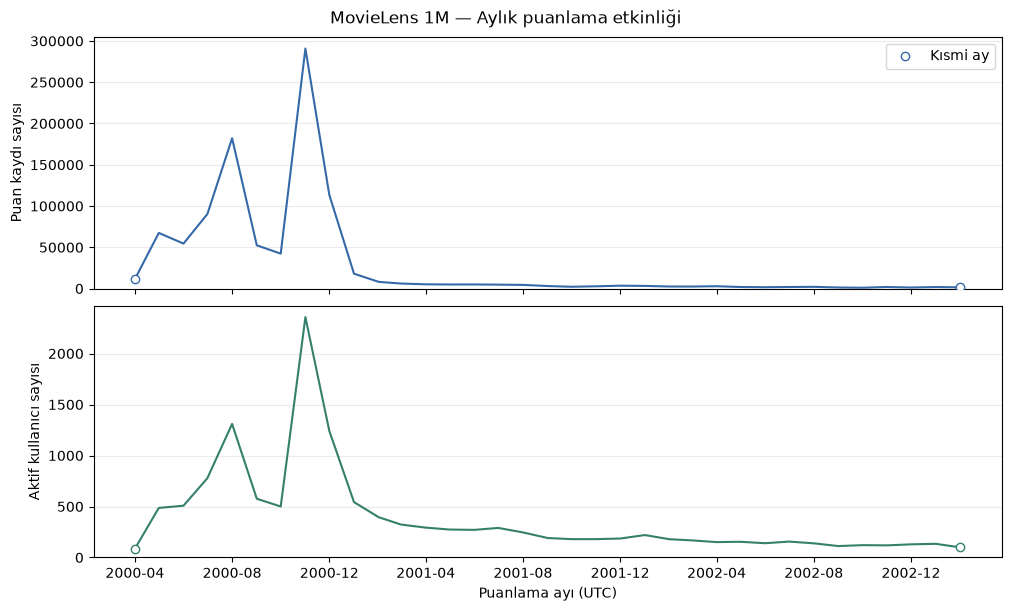

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

monthly_plot = monthly_activity.toPandas()
monthly_plot["rating_month"] = pd.to_datetime(monthly_plot["rating_month"])
monthly_plot = monthly_plot.sort_values("rating_month")

partial_months = monthly_plot.iloc[[0, -1]]

fig, (ax_ratings, ax_users) = plt.subplots(
    2, 1, figsize=(10, 6), sharex=True, layout="constrained"
)

for ax, column, label, color in [
    (ax_ratings, "rating_count", "Puan kaydı sayısı", "#3569A8"),
    (ax_users, "active_users", "Aktif kullanıcı sayısı", "#35806C"),
]:
    ax.plot(monthly_plot["rating_month"], monthly_plot[column], color=color)
    ax.scatter(
        partial_months["rating_month"],
        partial_months[column],
        facecolors="white",
        edgecolors=color,
        zorder=3,
        label="Kısmi ay",
    )
    ax.set_ylabel(label)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.25)

ax_ratings.legend()
ax_users.set_xlabel("Puanlama ayı (UTC)")
ax_users.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax_users.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

fig.suptitle("MovieLens 1M — Aylık puanlama etkinliği")
plt.show()

### Aylık puanlama etkinliğinin yorumu

Kasım 2000, 290.793 puan ve 2.357 aktif kullanıcıyla her iki ölçütte
de en yüksek aydır. Bu ay, veri setindeki tüm puanların %29,07’sini
içerir. Nisan 2000 ve Şubat 2003 gözlem aralığının kısmi aylarıdır.
Grafikte bu iki ayı içi boş daireyle işaretledim.

## CSV ve Parquet için deney verisinin hazırlanması

Doğrulanmış puan tablosunun aynı dört sütununu CSV ve Parquet olarak
kaydediyorum. Her iki çıktı aynı kayıtları içeriyor. Bir sonraki adımda
dosyaları yeniden okuyup şema, satır sayısı ve sorgu sonuçlarını
karşılaştıracağım.

In [30]:
import pyarrow as pa
import pyarrow.parquet as pq

benchmark_ratings = ratings.select("UserID", "MovieID", "Rating", "Timestamp")
benchmark_dir = project_root / "data" / "benchmark"
benchmark_dir.mkdir(parents=True, exist_ok=True)

csv_path = benchmark_dir / "ratings.csv"
parquet_path = benchmark_dir / "ratings.parquet"

benchmark_data = benchmark_ratings.toPandas()

parquet_schema = pa.schema([
    ("UserID", pa.int32()),
    ("MovieID", pa.int32()),
    ("Rating", pa.int32()),
    ("Timestamp", pa.int64()),
])

benchmark_data.to_csv(csv_path, index=False)
pq.write_table(
    pa.Table.from_pandas(
        benchmark_data, schema=parquet_schema, preserve_index=False
    ),
    parquet_path,
    compression="snappy",
)

print("Yazılan kaynak kayıt sayısı:", len(benchmark_data))
for file in [csv_path, parquet_path]:
    print(f"{file.name}: {file.stat().st_size:,} bayt")

Yazılan kaynak kayıt sayısı: 1000209
ratings.csv: 22,593,746 bayt
ratings.parquet: 5,311,430 bayt


### CSV ve Parquet dosyalarının geri okunması

CSV dosyasını puan tablosunun açık şemasıyla, Parquet dosyasını ise
kendi sakladığı şemayla okuyorum. İki dosyanın sütun adlarını,
tiplerini ve satır sayılarını kaynak puan tablosuyla karşılaştırıyorum.

In [31]:
csv_ratings = (
    spark.read
    .schema(benchmark_ratings.schema)
    .option("header", True)
    .option("mode", "FAILFAST")
    .csv(csv_path.as_uri())
)

parquet_ratings = spark.read.parquet(parquet_path.as_uri())

expected_columns = benchmark_ratings.dtypes

for name, table in [("CSV", csv_ratings), ("Parquet", parquet_ratings)]:
    row_count = table.count()
    print(f"{name} sütunları ve tipleri:", table.dtypes)
    print(f"{name} şeması kaynakla eşleşiyor:", table.dtypes == expected_columns)
    print(f"{name} satır sayısı:", row_count)
    print(f"{name} satır sayısı kaynakla eşleşiyor:", row_count == total_ratings)

CSV sütunları ve tipleri: [('UserID', 'int'), ('MovieID', 'int'), ('Rating', 'int'), ('Timestamp', 'bigint')]
CSV şeması kaynakla eşleşiyor: True
CSV satır sayısı: 1000209
CSV satır sayısı kaynakla eşleşiyor: True
Parquet sütunları ve tipleri: [('UserID', 'int'), ('MovieID', 'int'), ('Rating', 'int'), ('Timestamp', 'bigint')]
Parquet şeması kaynakla eşleşiyor: True
Parquet satır sayısı: 1000209
Parquet satır sayısı kaynakla eşleşiyor: True


### Deney sorgusunun doğrulanması

Üç veri kaynağına aynı tarih filtresini uyguluyorum. Mayıs 2000 ile
Ocak 2003 arasındaki tam takvim ayları için puan sayısını ve benzersiz
aktif kullanıcı sayısını hesaplıyorum. CSV ve Parquet sonuçlarını
hem birbirleriyle hem de kaynak puan tablosuyla karşılaştırıyorum.

In [32]:
from datetime import datetime, timezone

spark.conf.set("spark.sql.session.timeZone", "UTC")

start_ts = int(datetime(2000, 5, 1, tzinfo=timezone.utc).timestamp())
end_ts = int(datetime(2003, 2, 1, tzinfo=timezone.utc).timestamp())


def benchmark_monthly_activity(table):
    return (
        table.where(
            (F.col("Timestamp") >= start_ts) & (F.col("Timestamp") < end_ts)
        )
        .withColumn(
            "rating_month",
            F.date_trunc("month", F.timestamp_seconds("Timestamp")).cast("date"),
        )
        .groupBy("rating_month")
        .agg(
            F.count("*").alias("rating_count"),
            F.countDistinct("UserID").alias("active_users"),
        )
        .orderBy("rating_month")
    )


source_monthly_result = benchmark_monthly_activity(ratings).collect()
csv_monthly_result = benchmark_monthly_activity(csv_ratings).collect()
parquet_monthly_result = benchmark_monthly_activity(parquet_ratings).collect()

print("Karşılaştırılan ay sayısı:", len(source_monthly_result))
print("CSV ile kaynak sonucu aynı:", csv_monthly_result == source_monthly_result)
print("Parquet ile kaynak sonucu aynı:", parquet_monthly_result == source_monthly_result)
print("CSV ile Parquet sonucu aynı:", csv_monthly_result == parquet_monthly_result)

Karşılaştırılan ay sayısı: 33
CSV ile kaynak sonucu aynı: True
Parquet ile kaynak sonucu aynı: True
CSV ile Parquet sonucu aynı: True


### CSV ve Parquet okuma ve sorgu sürelerinin karşılaştırılması

Her biçim için bir ısınma koşusu ve beş ölçüm yapıyorum. Her koşuda
dosyayı Spark ile yeniden okuyup aynı aylık sorguyu çalıştırıyorum.
Süreyi okumadan hemen önce başlatıp `collect()` sonucu döndürdüğünde
durduruyorum. Ölçüm turlarında hangi biçimin önce çalıştığını
değiştiriyorum ve her biçimin medyan süresini hesaplıyorum.

In [33]:
from statistics import median
from time import perf_counter


def read_benchmark_file(file_format):
    if file_format == "CSV":
        return (
            spark.read
            .schema(benchmark_ratings.schema)
            .option("header", True)
            .option("mode", "FAILFAST")
            .csv(csv_path.as_uri())
        )

    return spark.read.parquet(parquet_path.as_uri())


def time_monthly_query(file_format):
    started_at = perf_counter()
    table = read_benchmark_file(file_format)
    result = benchmark_monthly_activity(table).collect()
    elapsed_seconds = perf_counter() - started_at

    if result != source_monthly_result:
        raise ValueError(f"{file_format} sonucu kaynak sorguyla eşleşmedi.")

    return elapsed_seconds


formats = ("CSV", "Parquet")
timings = {"CSV": [], "Parquet": []}

for file_format in formats:
    elapsed = time_monthly_query(file_format)
    print(f"Isınma | {file_format}: {elapsed:.3f} sn")

for run in range(1, 6):
    run_order = formats if run % 2 == 1 else formats[::-1]
    for file_format in run_order:
        elapsed = time_monthly_query(file_format)
        timings[file_format].append(elapsed)
        print(f"Tur {run} | {file_format}: {elapsed:.3f} sn")

print("\nMedyan süreler")
for file_format, seconds in timings.items():
    print(f"{file_format}: {median(seconds):.3f} sn ({len(seconds)} ölçüm)")

Isınma | CSV: 1.345 sn
Isınma | Parquet: 0.868 sn
Tur 1 | CSV: 1.264 sn
Tur 1 | Parquet: 0.981 sn
Tur 2 | Parquet: 0.868 sn
Tur 2 | CSV: 1.474 sn
Tur 3 | CSV: 1.339 sn
Tur 3 | Parquet: 0.842 sn
Tur 4 | Parquet: 0.882 sn
Tur 4 | CSV: 1.514 sn
Tur 5 | CSV: 1.170 sn
Tur 5 | Parquet: 0.939 sn

Medyan süreler
CSV: 1.339 sn (5 ölçüm)
Parquet: 0.882 sn (5 ölçüm)


### CSV–Parquet deneyinin sonucu

Aynı 1.000.209 puan kaydını iki dosya biçiminde sakladım. Spark ile
Mayıs 2000–Ocak 2003 arasındaki her ay için puan sayısını ve benzersiz
aktif kullanıcı sayısını hesapladım. İki dosya da 33 ayın tamamında
kaynak puan tablosuyla aynı sonuçları verdi.

| Ölçüm | CSV (sıkıştırılmamış) | Parquet (Snappy) |
| --- | ---: | ---: |
| Dosya boyutu | 22.593.746 bayt | 5.311.430 bayt |
| Okuma ve sorgu süresi (5 ölçümün medyanı) | 1,221 sn | 0,823 sn |

Bu deneyde Parquet dosyası %76,5 daha az yer kapladı. Aynı aylık
sonucu almak medyan olarak 0,398 saniye daha kısa sürdü.
Bu, CSV'ye göre yaklaşık %32,6 daha kısa süre demek.

Süreyi dosyayı okumaya başlamadan hemen önce başlattım ve `collect()`
aylık sonuçları döndürdüğünde durdurdum. Dosyaları oluşturma süresi
ölçüme dahil değildi. Her biçim için bir ısınma koşusu yaptım ve
ölçüm turlarında çalışma sırasını değiştirdim. Sonuçlar bu bilgisayar,
veri, sorgu ve sıkıştırma ayarları için geçerli. Tekrarlanan
okumalarda işletim sistemi önbelleği süreleri etkilemiş olabilir.